# 📊 Класс `CLAFrontier`: Полный обзор

Класс `CLAFrontier` представляет собой объектно-ориентированную обертку (Wrapper) над алгоритмом `CLA` из библиотеки `PyPortfolioOpt`. Он инкапсулирует всю логику работы с эффективной границей: от первичного расчета и математической фильтрации «шумных» угловых портфелей до поиска оптимального портфеля и визуализации.

Главная цель класса — избавить исследователя от дублирования кода в Jupyter Notebook и предоставить готовый, переиспользуемый инструмент для портфельного анализа.

---

## 🏗️ Архитектура и атрибуты класса

При создании экземпляра класса (`__init__`) происходит базовый расчет эффективной границы, результаты которого сохраняются в атрибуты объекта:

*   **`self.mu`**: `np.ndarray` — вектор ожидаемых доходностей активов.
*   **`self.S`**: `np.ndarray` — ковариационная матрица доходностей.
*   **`self.cla`**: `pypfopt.CLA` — внутренний объект оптимизатора.
*   **`self.raw_returns`**: `list` — «сырые» значения доходностей всех найденных CLA точек.
*   **`self.raw_volatilities`**: `list` — «сырые» значения волатильности (риска).
*   **`self.raw_weights`**: `list` — массивы весов активов для всех найденных точек.

---

## 🛠️ Детальный разбор методов

### 1. `get_filtered_turning_points(tol=1e-4)`
Метод решает проблему **численного шума** (floating-point artifacts), из-за которого классический CLA генерирует десятки лишних угловых портфелей для небольшого числа активов.

*   **Логика работы:** Метод создает булеву «маску» активных активов для каждой точки. Активным считается тот, чей вес попадает в интервал \((tol, 1 - tol)\). Если маска текущей точки совпадает с предыдущей (состав активов не изменился), точка отбрасывается как «мусорная». Сохраняются только те точки, где происходит реальная смена состава портфеля.
*   **Параметры:** `tol` (порог чувствительности, по умолчанию `1e-4`).
*   **Возвращает:** `pd.DataFrame` с колонками `['returns', 'volatilities', 'weights']`. Возврат в формате DataFrame крайне удобен для дальнейшей фильтрации и анализа.

### 2. `get_optimal_portfolio()`
Метод находит **касательный портфель** (портфель с максимальным коэффициентом Шарпа).

*   **Логика работы:** Использует встроенный метод `self.cla.max_sharpe()`. Так как классический `CLA` в `PyPortfolioOpt` по умолчанию работает с нулевой безрисковой ставкой, метод находит оптимальную точку именно для `rf = 0`.
*   **Возвращает:** Словарь (`dict`) с ключами:
    *   `"returns"`: ожидаемая доходность оптимального портфеля.
    *   `"volatilities"`: волатильность (риск).
    *   `"weights"`: `np.ndarray` весов активов.
    *   `"sharpe"`: рассчитанный коэффициент Шарпа.

### 3. `plot_frontier(ax=None)`
Метод для визуализации эффективной границы, повторяющий логику из предоставленного Jupyter Notebook.

*   **Логика работы:** Рисует сплошную полупрозрачную линию по всем `self.raw_volatilities` и `self.raw_returns`. Поверх неё наносит точки, полученные из `get_filtered_turning_points()` в виде ромбов (`marker='D'`). Метод возвращает объект `ax`, что позволяет легко добавлять другие графики поверх.
*   **Возвращает:** `matplotlib.axes.Axes` (систему координат для рисования).

### 4. `plot_cml(ax=None)`
Метод для построения **Линии рынка капитала (CML)** и визуализации оптимального портфеля.

*   **Логика работы:** Вызывает `get_optimal_portfolio()` для получения точки касания. Рисует саму точку в виде золотой звезды. Затем строит прямую линию (CML) от точки безрисковой ставки `(0, 0)` с наклоном, равным максимальному коэффициенту Шарпа.
*   **Возвращает:** `matplotlib.axes.Axes`.

Данные успешно подготовлены. Количество активов: 10

Инициализация CLA и расчет границы...

📊 ОТФИЛЬТРОВАННЫЕ УГЛОВЫЕ ПОРТФЕЛИ
Найдено точек (со сменой состава): 12
  returns volatilities
0  24.01%       29.71%
1  23.96%       29.01%
2  23.51%       24.85%
3  23.02%       21.76%
4  21.58%       15.18%

🎯 ОПТИМАЛЬНЫЙ ПОРТФЕЛЬ (Max Sharpe, rf=0)
Ожидаемая доходность : 14.50%
Волатильность (риск) : 7.25%
Коэффициент Шарпа    : 1.9998

Веса активов:
  Актив  3: 7.64%
  Актив  4: 16.88%
  Актив  5: 22.45%
  Актив  6: 12.50%
  Актив  7: 2.97%
  Актив  8: 9.01%
  Актив  9: 15.42%
  Актив 10: 12.52%

Построение графиков...


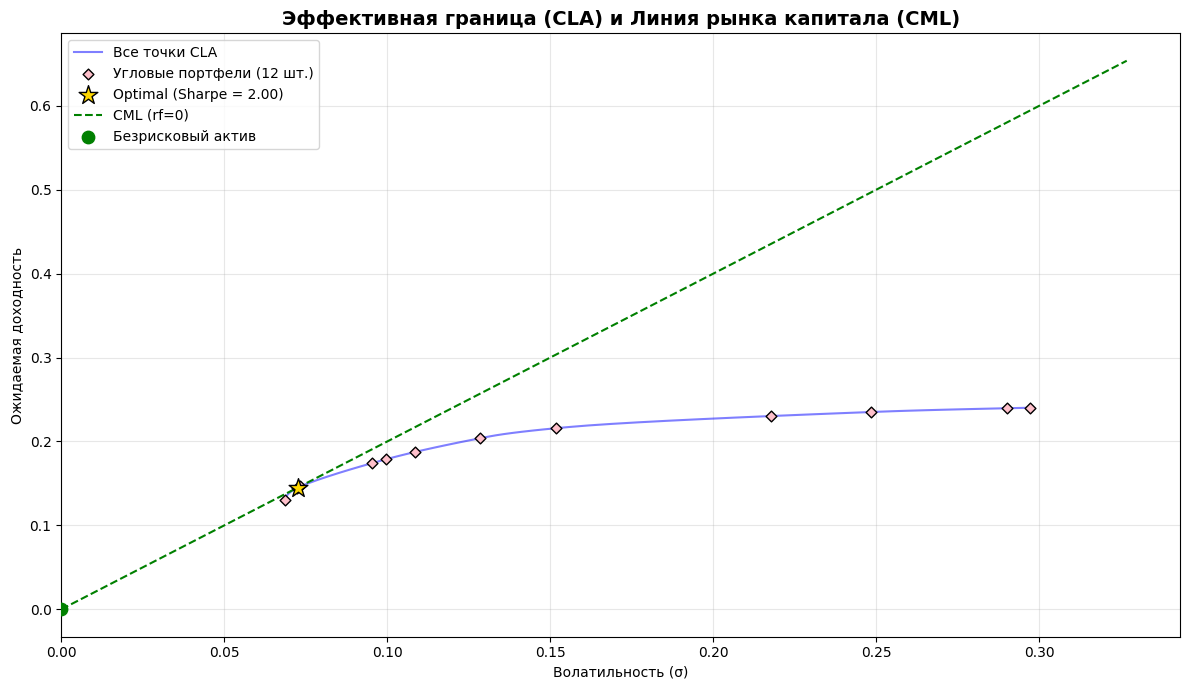

In [1]:
from classCLAFrontier import CLAFrontier
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================================
# 1. ПОДГОТОВКА ДАННЫХ
# =====================================================================
# (В вашем проекте здесь будет загрузка mu и S из prices_processed.csv)

np.random.seed(42) # Для воспроизводимости результатов
n_assets = 10

# Генерируем случайные ожидаемые доходности (от 5% до 25%)
mu = np.random.uniform(0.05, 0.25, n_assets)

# Генерируем валидную (положительно полуопределенную) ковариационную матрицу
A = np.random.randn(n_assets, n_assets)
S = A @ A.T * 0.01 

print("Данные успешно подготовлены. Количество активов:", n_assets)

# =====================================================================
# 2. ИНИЦИАЛИЗАЦИЯ И РАСЧЕТ
# =====================================================================
print("\nИнициализация CLA и расчет границы...")
frontier = CLAFrontier(mu, S)

# Получаем отфильтрованные угловые портфели (Задача 1)
df_clean = frontier.get_filtered_turning_points()

# Получаем касательный портфель (Задача 3)
optimal = frontier.get_optimal_portfolio()

# =====================================================================
# 3. ВЫВОД РЕЗУЛЬТАТОВ В КОНСОЛЬ
# =====================================================================
print("\n" + "="*50)
print("📊 ОТФИЛЬТРОВАННЫЕ УГЛОВЫЕ ПОРТФЕЛИ")
print("="*50)
print(f"Найдено точек (со сменой состава): {len(df_clean)}")
# Выводим первые 5 строк для наглядности
print(df_clean[['returns', 'volatilities']].head().to_string(
    formatters={'returns': '{:.2%}'.format, 'volatilities': '{:.2%}'.format}
))

print("\n" + "="*50)
print("🎯 ОПТИМАЛЬНЫЙ ПОРТФЕЛЬ (Max Sharpe, rf=0)")
print("="*50)
print(f"Ожидаемая доходность : {optimal['returns']:.2%}")
print(f"Волатильность (риск) : {optimal['volatilities']:.2%}")
print(f"Коэффициент Шарпа    : {optimal['sharpe']:.4f}")
print("\nВеса активов:")
# Красиво выводим только те активы, чей вес больше 1%
for i, w in enumerate(optimal['weights']):
    if w > 0.01:
        print(f"  Актив {i+1:2d}: {w:.2%}")

# =====================================================================
# 4. ВИЗУАЛИЗАЦИЯ (Задачи 2 и 4)
# =====================================================================
print("\nПостроение графиков...")

fig, ax = plt.subplots(figsize=(12, 7))

# Рисуем границу и отфильтрованные точки
frontier.plot_frontier(ax=ax)

# Рисуем CML, безрисковую ставку и оптимальную точку
frontier.plot_cml(ax=ax)

# Немного кастомизируем общий график
ax.set_title("Эффективная граница (CLA) и Линия рынка капитала (CML)", fontsize=14, fontweight='bold')
ax.set_xlim(left=0) # Начинаем ось X с нуля
plt.tight_layout()
plt.show()